# SymPhase tutorial 5 — finite-temperature convex hulls

$$G_i(T)=E_i+F^{\rm vib}_i(T)-T\,S^{\rm conf}_i ,\qquad
S^{\rm conf}=-k_B\frac{\sum_s m_s\sum_a x_{s,a}\ln x_{s,a}}{\sum_s m_s}$$

* **mixing entropy** from a sublattice spec per entry (CSV column `mixing`, e.g. `Ti0.5Zr0.5|Ni|Sn`) or `s_config` (k$_B$/atom),
* **vibrations**: `debye` (column `debye_T`), `phonopy` (`total_dos.dat` or `thermal_properties.yaml`, column `phonons`),
  `bartel` (SISSO descriptor via pymatgen, 300–2000 K), or `none`.

> Toy energies and Debye temperatures (see `examples/hull/make_toy_data.py`).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
from symphase.hull import load_csv
from symphase.thermo import FiniteTHull, parse_mixing
import math
print("S_conf of (Ti0.5Zr0.5)NiSn:", parse_mixing("Ti0.5Zr0.5|Ni|Sn")[0], "k_B/atom  = ln2/3 =", math.log(2) / 3)
ents = load_csv(f"{EX}/hull/TiZrNiSn_quaternary.csv")
ft = FiniteTHull(ents, vib="none")              # mixing entropy only
ft.scan([0, 200, 300, 400, 600, 900, 1200])
ft.report()

S_conf of (Ti0.5Zr0.5)NiSn: 0.23104906018664842 k_B/atom  = ln2/3 = 0.23104906018664842



Finite-temperature hull  (vibrations: none, mixing entropy: on)
  name                              0K      200K      300K      400K      600K      900K     1200K   S_conf(kB/at)   T_stab
  -------------------------------------------------------------------------------------------------------------------------
  stable at all temperatures (23): Ti-hcp, Ni-fcc, Sn-alpha, TiNi-B2, TiNi3-D024, Ti2Ni-E93, Ni3Sn-D019, Ni3Sn2-B81, Ni3Sn4-mC14, Ti3Sn-D019, Ti5Sn3-D88, Ti6Sn5-hP22, TiSn2-hyp, TiNiSn-HH, TiNi2Sn-FH, Zr-hcp, ZrNi-B33, ZrNi3-D019, Zr2Ni-C16, Zr5Sn3-D88, ZrSn2-C54, ZrNiSn-HH, ZrNi2Sn-FH


  TiZr-bcc                        20.0       8.1       2.1       0.0       0.0       0.0       0.0        0.693         335 K


  (Ti0.5Zr0.5)NiSn-SQS             5.0       1.0       0.0       0.0       0.0       0.0       0.0        0.231         251 K


  (Ti0.75Zr0.25)NiSn-SQS           4.5       1.3       0.1       0.0       0.0       0.0       0.0        0.187         323 K


  (Ti0.25Zr0.75)NiSn-SQS           5.5       2.3       1.1       0.5       0.0       0.0       0.0        0.187         484 K


  (TiZr)Ni2Sn-SQS                 12.5       9.5       8.0       6.5       3.5       0.0       0.0        0.173         837 K
  Ti2Sn-B82                       23.3      23.3      23.3      23.3      23.3      23.3      23.3        0.000     -
  Zr4Sn-A15                       25.3      25.3      25.3      25.3      25.3      25.3      25.3        0.000     -
  TiNiSn-other                    50.0      50.0      50.0      50.0      50.0      50.0      50.0        0.000     -
  Ti2NiSn-inverseHeusler          57.8      57.8      57.8      57.8      57.8      57.8      57.8        0.000     -
  Ti2Ni2Sn-hyp                    58.0      58.0      58.0      58.0      58.0      58.0      58.0        0.000     -
  Ti-bcc                          60.0      60.0      60.0      60.0      60.0      60.0      60.0        0.000     -
  NiSn-hyp                        67.5      67.5      67.5      67.5      67.5      67.5      67.5        0.000     -
  TiNi2-hyp                      103.3     103.3

The 5 meV/atom mixing enthalpy of (Ti$_{0.5}$Zr$_{0.5}$)NiSn is overcome when $k_BT\ln2/3=5$ meV, i.e.
$T^*=251$ K — SymPhase finds it by bisection. Adding Debye phonons:


Finite-temperature hull  (vibrations: debye, mixing entropy: on)
  name                              0K      200K      300K      400K      600K      900K     1200K   S_conf(kB/at)   T_stab
  -------------------------------------------------------------------------------------------------------------------------
  stable at all temperatures (22): Ti-hcp, Ni-fcc, Sn-alpha, TiNi-B2, TiNi3-D024, Ti2Ni-E93, Ni3Sn-D019, Ni3Sn2-B81, Ni3Sn4-mC14, Ti3Sn-D019, Ti5Sn3-D88, Ti6Sn5-hP22, TiNiSn-HH, TiNi2Sn-FH, Zr-hcp, ZrNi-B33, ZrNi3-D019, Zr2Ni-C16, Zr5Sn3-D88, ZrSn2-C54, ZrNiSn-HH, ZrNi2Sn-FH


  TiSn2-hyp                        0.0       0.0       0.0       0.0       0.0       0.3       2.2        0.000     stable ≤ 858 K


  TiZr-bcc                        20.0       8.8       3.3       0.0       0.0       0.0       0.0        0.693         360 K


  (Ti0.5Zr0.5)NiSn-SQS             5.0       1.1       0.0       0.0       0.0       0.0       0.0        0.231         255 K


  (Ti0.75Zr0.25)NiSn-SQS           4.5       1.3       0.2       0.0       0.0       0.0       0.0        0.187         327 K


  (Ti0.25Zr0.75)NiSn-SQS           5.5       2.3       1.2       0.6       0.0       0.0       0.0        0.187         491 K


  (TiZr)Ni2Sn-SQS                 12.5       9.6       8.1       6.6       3.7       0.0       0.0        0.173         850 K
  Ti2Sn-B82                       23.3      23.4      23.4      23.4      23.4      23.5      23.5        0.000     -
  Zr4Sn-A15                       25.3      25.4      25.5      25.5      25.6      25.8      25.9        0.000     -
  Ti2Ni2Sn-hyp                    55.2      53.6      52.0      50.2      46.7      41.2      36.0        0.000     -
  Ti2NiSn-inverseHeusler          55.6      54.4      53.2      51.8      49.1      44.9      40.7        0.000     -
  TiNiSn-other                    49.0      48.5      47.9      47.3      46.0      44.1      42.2        0.000     -
  Ti-bcc                          60.0      60.0      60.0      60.0      60.0      60.0      60.0        0.000     -
  NiSn-hyp                        67.5      67.6      67.7      67.7      67.8      68.0      68.1        0.000     -
  TiNi2-hyp                      103.3     103.3

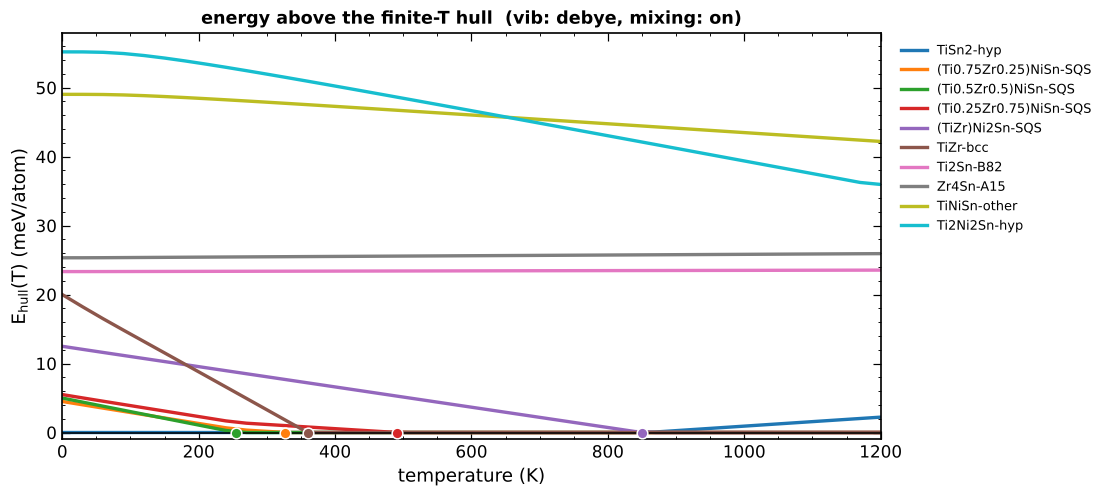

In [3]:
ftd = FiniteTHull(ents, vib="debye")
ftd.scan([0, 200, 300, 400, 600, 900, 1200]); ftd.report()
fig = ftd.plot_ehull_vs_T()

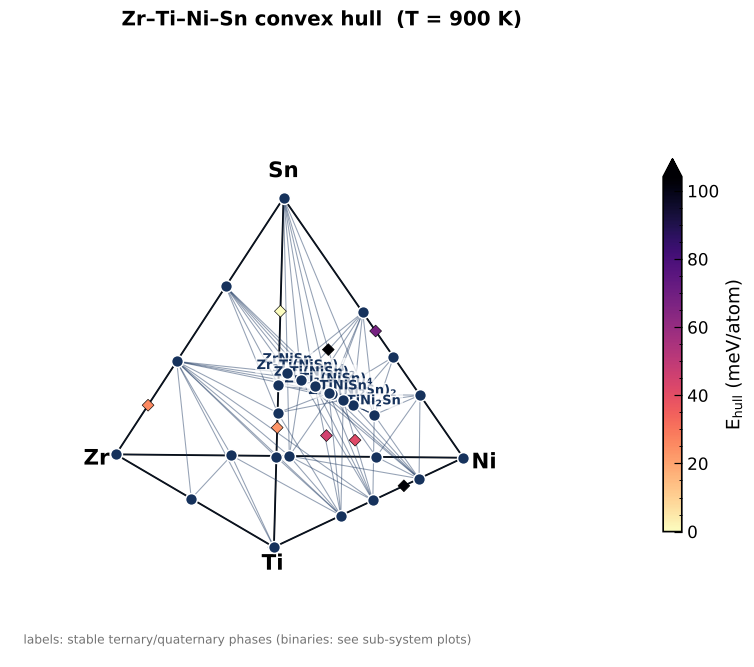

In [4]:
fig = ftd.plot_hull_at(900)

## Command line

```bash
symphase hull --csv data.csv --temperatures 300 600 900 1200 --vib debye
symphase hull --csv data.csv --temperatures 300 900 --vib phonopy      # 'phonons' column -> phonopy files
symphase hull --scan calcs/ --temperatures 600 1200 --vib bartel        # needs structures
symphase run Ti Zr Ni Sn temperatures="300 600 900 1200" vib=bartel     # automatic pipeline
```